/Users/jolespin/miniforge3/envs/hierarchical/lib/python3.10/site-packages/hierarchical_ensemble_classifier/__init__.py:338: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'versicolor' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  Y.loc[idx, node] = child
/Users/jolespin/miniforge3/envs/hierarchical/lib/python3.10/site-packages/hierarchical_ensemble_classifier/__init__.py:338: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'setosa' has dtype incompatible with float64, please explicitly cast to a compatible dtype first.
  Y.loc[idx, node] = child


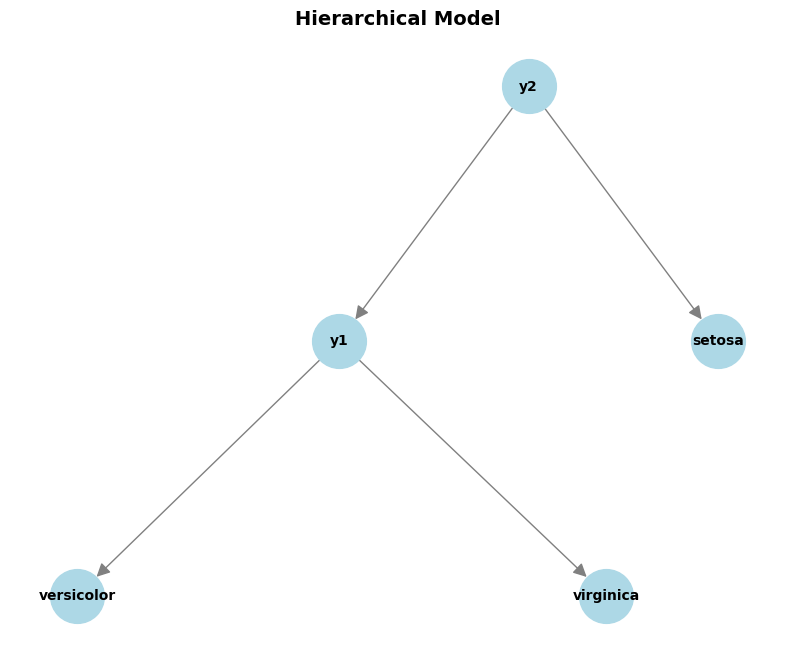

In [3]:
import pandas as pd
import numpy as np
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from hierarchical_ensemble_classifier import HierarchicalEnsembleClassifier, HierarchyBuilder

from sklearn.datasets import load_iris
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
import pandas as pd

# Load data
iris = load_iris()
X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target_names[iris.target])

# Build hierarchy from eigenprofiles
builder = HierarchyBuilder(linkage='ward')
builder.fit(X, y)
hierarchy = builder.get_hierarchy()
Y = builder.get_targets()

# Define estimators with different features
estimators = {
    'y1': {
        'features': ['sepal length (cm)', 'sepal width (cm)'],
        'classifier': LogisticRegression(random_state=0)
    },
    'y2': {
        'features': ['petal length (cm)', 'petal width (cm)'],
        'classifier': DecisionTreeClassifier(random_state=0)
    }
}

# Train hierarchical classifier
clf = HierarchicalEnsembleClassifier(hierarchy, estimators)
clf.fit(X, y)

# Make predictions
predictions = clf.predict(X)
probabilities = clf.predict_proba(X)

# Visualize
fig, ax = clf.plot_model()

In [5]:
hierarchy.nodes()
# NodeView(('root', 'cluster_0', 'setosa', 'versicolor', 'virginica'))

NodeView(('y1', 'versicolor', 'virginica', 'y2', 'setosa'))

In [7]:
builder.Y_

,y1,y2
0,NaN,setosa
1,NaN,setosa
2,NaN,setosa
3,NaN,setosa
4,NaN,setosa
...,...,...
145,virginica,y1
146,virginica,y1
147,virginica,y1
148,virginica,y1
